# Búsqueda de un rostro en una galería de fotos

Este cuaderno resuelve un problema de **identificación 1:N**: tenemos a una persona **inscrita** (la que queremos encontrar) y una **galería** de fotos donde puede aparecer, sola o acompañada. El sistema debe **detectar todas las caras** de la galería y decidir cuáles corresponden a la persona inscrita.

Es exactamente lo que hace, por ejemplo, "buscar todas las fotos de una persona" en una aplicación de álbumes. La tubería es:

1. **Inscripción:** se detecta y recorta el rostro de la persona buscada, y se calcula su ***embedding*** (vector de 512 números) con **AdaFace**.
2. **Detección en la galería:** con **MTCNN** se localizan *todas* las caras de *todas* las fotos.
3. **Embeddings de la galería:** cada cara detectada se convierte en su propio *embedding*.
4. **Comparación:** se mide la **similitud coseno** entre el inscrito y cada cara de la galería.
5. **Decisión:** las caras cuya similitud supera un **umbral** se marcan como coincidencias.

> AdaFace (*Quality Adaptive Margin for Face Recognition*, CVPR 2022) es robusto a imágenes de calidad dispar, lo que ayuda cuando las fotos de la galería no son todas nítidas ni frontales. [[paper]](https://openaccess.thecvf.com/content/CVPR2022/papers/Kim_AdaFace_Quality_Adaptive_Margin_for_Face_Recognition_CVPR_2022_paper.pdf)

---
*Traducido, adaptado y ampliado por Diego — material docente del curso de Visión por Computadora (Pontificia Universidad Católica de Chile).*

## 1. Librerías

Clonamos AdaFace, descargamos los pesos del modelo `ir_50` e instalamos MTCNN (detección de rostros) y OpenCV.

In [ ]:
# Repositorio oficial de AdaFace + pesos preentrenados (modelo ir_50, MS1MV2)
!git clone https://github.com/mk-minchul/AdaFace
!mkdir -p /content/AdaFace/pretrained
!gdown https://drive.google.com/uc?id=1eUaSHG4pGlIZK7hBkqjyp2fc2epKoBvI
!mv adaface_ir50_ms1mv2.ckpt /content/AdaFace/pretrained/adaface_ir50_ms1mv2.ckpt
!pip install -q pytorch-lightning

Cloning into 'AdaFace'...
remote: Enumerating objects: 236, done.
remote: Counting objects: 100% (107/107), done.
remote: Compressing objects: 100% (51/51), done.
remote: Total 236 (delta 66), reused 56 (delta 56), pack-reused 129 (from 1)
Receiving objects: 100% (236/236), 38.95 MiB | 18.28 MiB/s, done.
Resolving deltas: 100% (88/88), done.
Downloading...
From (original): https://drive.google.com/uc?id=1eUaSHG4pGlIZK7hBkqjyp2fc2epKoBvI
From (redirected): https://drive.google.com/uc?id=1eUaSHG4pGlIZK7hBkqjyp2fc2epKoBvI&confirm=t&uuid=c4e52023-f817-4487-a64c-99eb69c20659
To: /content/adaface_ir50_ms1mv2.ckpt
100% 700M/700M [00:08<00:00, 83.8MB/s]
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 852.4/852.4 kB 20.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 983.4/983.4 kB 60.7 MB/s eta 0:00:00


In [ ]:
!pip install -q mtcnn
!pip install -q opencv-contrib-python

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.9/1.9 MB 24.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 35.5 MB/s eta 0:00:00


In [ ]:
import cv2
import matplotlib.pyplot as plt
import numpy as np
from tqdm.auto import tqdm
import os, fnmatch
from mtcnn.mtcnn import MTCNN
from PIL import Image
import torch
import torch.nn as nn

## 2. Descarga de la base de datos

Descargamos y descomprimimos los datos. El paquete contiene:

* La foto de la persona **inscrita** (la que vamos a buscar): `diego.jpeg`.
* La **galería** de fotos donde buscarla, en la carpeta `images/`.

> Si quieres usar tu propia base, reemplaza esta celda por la descarga (o subida) de tus archivos, manteniendo la misma estructura: una foto del rostro inscrito y una carpeta con la galería.

In [ ]:
!wget -q -O data.zip \
"https://www.dropbox.com/scl/fi/1newelyagzp746zumlkpj/data.zip?rlkey=h2sxf92b2c5bakao5zut3co7d&dl=1"
!unzip -qq data.zip
print('Datos descargados y descomprimidos.')

Datos descargados y descomprimidos.


## 3. Carga del modelo AdaFace

Importamos las utilidades del repositorio y cargamos el modelo `ir_50` en modo evaluación.

> En versiones recientes de PyTorch, `torch.load` es más estricto por seguridad; por eso registramos `ModelCheckpoint` como *safe global* antes de cargar el *checkpoint*.

In [ ]:
%cd /content/AdaFace
from face_alignment import align
from inference import load_pretrained_model, to_input
from pytorch_lightning.callbacks import ModelCheckpoint

torch.serialization.add_safe_globals([ModelCheckpoint])

model = load_pretrained_model('ir_50')
print('Modelo AdaFace ir_50 cargado correctamente.')

/content/AdaFace


/content/AdaFace/face_alignment/mtcnn_pytorch/src/align_trans.py:287: SyntaxWarning: "is" with 'str' literal. Did you mean "=="?
  if align_type is 'cv2_affine':
/content/AdaFace/face_alignment/mtcnn_pytorch/src/align_trans.py:290: SyntaxWarning: "is" with 'str' literal. Did you mean "=="?
  elif align_type is 'affine':


Modelo AdaFace ir_50 cargado correctamente.


## 4. Funciones auxiliares

- `fx_adaface(A)`: recibe el recorte de un rostro (en BGR de OpenCV), lo lleva a 112×112 y devuelve su *embedding* de 512 elementos.
- `dirfiles(...)`: lista los archivos de una carpeta que calzan con un patrón.

> Nota técnica: aquí calculamos el *embedding* directamente sobre el recorte del *bounding box*, sin el alineamiento fino por puntos faciales que ofrece `align.get_aligned_face`. Es más simple y suele bastar para rostros frontales; si necesitas máxima precisión, alinear con los *landmarks* mejora los resultados.

In [ ]:
def fx_adaface(A):
    '''Calcula el embedding AdaFace (1x512) de un recorte de rostro en BGR.'''
    img       = cv2.resize(A, (112, 112))
    convertida = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    pil_image = Image.fromarray(convertida)
    bgr_input = to_input(pil_image)
    features, _ = model(bgr_input)
    X = features.detach().numpy()      # embeddings ya normalizados (norma 1)
    return X


def dirfiles(img_path, img_ext):
    '''Lista, ordenados, los archivos de img_path que calzan con el patrón img_ext.'''
    return fnmatch.filter(sorted(os.listdir(img_path)), img_ext)

In [ ]:
# Detector de rostros (MTCNN)
detector = MTCNN()

## 5. Rostro inscrito (la persona a buscar)

Leemos la foto de la persona inscrita, detectamos su rostro con MTCNN, lo recortamos y lo mostramos.

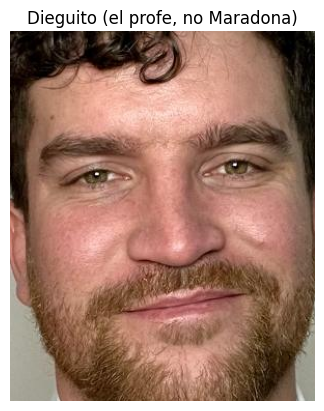

In [ ]:
RUTA_INSCRITO = '/content/diego.jpeg'   # cambia esta ruta para inscribir a otra persona

Ao = cv2.imread(RUTA_INSCRITO)
detecciones = detector.detect_faces(Ao)
bb = detecciones[0]['box']
x1, y1 = bb[0], bb[1]
x2, y2 = bb[0] + bb[2], bb[1] + bb[3]
A = Ao[y1:y2, x1:x2, :]      # recorte del rostro inscrito

plt.imshow(cv2.cvtColor(A, cv2.COLOR_BGR2RGB))
plt.title('Dieguito (el profe, no Maradona)')
plt.axis('off')
plt.show()

### Embedding del rostro inscrito

Guardamos su *embedding* en la variable `X` (un vector de 512 elementos). Será nuestra "consulta".

In [ ]:
X = fx_adaface(A)
print('Embedding del inscrito:', X.shape)

/content/AdaFace/inference.py:25: UserWarning: Creating a tensor from a list of numpy.ndarrays is extremely slow. Please consider converting the list to a single numpy.ndarray with numpy.array() before converting to a tensor. (Triggered internally at /pytorch/torch/csrc/utils/tensor_new.cpp:253.)
  tensor = torch.tensor([brg_img.transpose(2,0,1)]).float()


Embedding del inscrito: (1, 512)


## 6. Detección de las caras de la galería

Detectamos **todas** las caras de **todas** las fotos de la galería. El resultado es un arreglo `BB` de `N × 5`, donde `N` es el total de caras encontradas. Por cada cara guardamos:

* `k`: número de la foto de la galería donde aparece.
* `x1, y1`: esquina superior izquierda del *bounding box*.
* `x2, y2`: esquina inferior derecha del *bounding box*.

In [ ]:
ipath = '/content/images/'
fotos = dirfiles(ipath, '*.jpeg')
print('Galería de fotos:', fotos)

Galería de fotos: ['test_01.jpeg', 'test_02.jpeg', 'test_03.jpeg', 'test_04.jpeg', 'test_05.jpeg', 'test_06.jpeg', 'test_07.jpeg', 'test_08.jpeg']


In [ ]:
m = len(fotos)
BB = []
for k in range(m):
    img_path = ipath + fotos[k]
    print(f'{k}/{m} procesando imagen {img_path}')
    I = cv2.imread(img_path)
    caras = detector.detect_faces(I)
    print(f'  {len(caras)} cara(s) detectada(s)')
    for cara in caras:
        bbox = cara['box']
        x1 = bbox[0]
        y1 = bbox[1]
        x2 = bbox[0] + bbox[2]
        y2 = bbox[1] + bbox[3]
        BB.append([k, x1, y1, x2, y2])

N = len(BB)
print(f'\n{N} caras detectadas en {m} imágenes')

0/8 procesando imagen /content/images/test_01.jpeg
  7 cara(s) detectada(s)
1/8 procesando imagen /content/images/test_02.jpeg
  6 cara(s) detectada(s)
2/8 procesando imagen /content/images/test_03.jpeg
  4 cara(s) detectada(s)
3/8 procesando imagen /content/images/test_04.jpeg
  16 cara(s) detectada(s)
4/8 procesando imagen /content/images/test_05.jpeg
  1 cara(s) detectada(s)
5/8 procesando imagen /content/images/test_06.jpeg
  4 cara(s) detectada(s)
6/8 procesando imagen /content/images/test_07.jpeg
  4 cara(s) detectada(s)
7/8 procesando imagen /content/images/test_08.jpeg
  6 cara(s) detectada(s)

48 caras detectadas en 8 imágenes


## 7. Embeddings de la galería

Usando el arreglo `BB`, construimos una matriz `Y` de `N × 512`: la fila `j` de `Y` contiene el *embedding* de la cara descrita en la fila `j` de `BB`.

In [ ]:
Y = np.zeros((N, 512))
for j in tqdm(range(N)):
    k, x1, y1, x2, y2 = BB[j]
    I = cv2.imread(ipath + fotos[k])   # foto de la galería
    cara = I[y1:y2, x1:x2, :]          # recorte de la cara detectada
    Y[j, :] = fx_adaface(cara)
print('Matriz de embeddings de la galería:', Y.shape)

  0%|          | 0/48 [00:00<?, ?it/s]

Matriz de embeddings de la galería: (48, 512)


## 8. Comparación (*matching*)

Multiplicamos el *embedding* inscrito `X` por todos los de la galería `Y`. Como los *embeddings* están normalizados, el producto punto **es la similitud coseno**. Las caras cuya similitud supere el **umbral** se consideran coincidencias.

El umbral es **ajustable**: subirlo evita falsos positivos (aceptar a otra persona) pero puede dejar fuera coincidencias válidas; bajarlo hace lo contrario. El valor original del cuaderno era 0.2.

In [ ]:
UMBRAL = 0.3                       # ajústalo según tu punto de operación
score  = np.dot(X, Y.T)[0]         # similitud coseno con cada cara de la galería
detect = score > UMBRAL            # vector booleano de coincidencias

print(f'{int(detect.sum())} de {N} caras superan el umbral ({UMBRAL}).')

7 de 48 caras superan el umbral (0.2).


## 9. Resultados ordenados por similitud

Así es como un buscador de rostros presenta sus resultados: **todas las caras detectadas, ordenadas de mayor a menor parecido** con la persona inscrita. En verde, las que superan el umbral (coincidencias); en rojo, las descartadas. Sobre cada una, su puntaje.

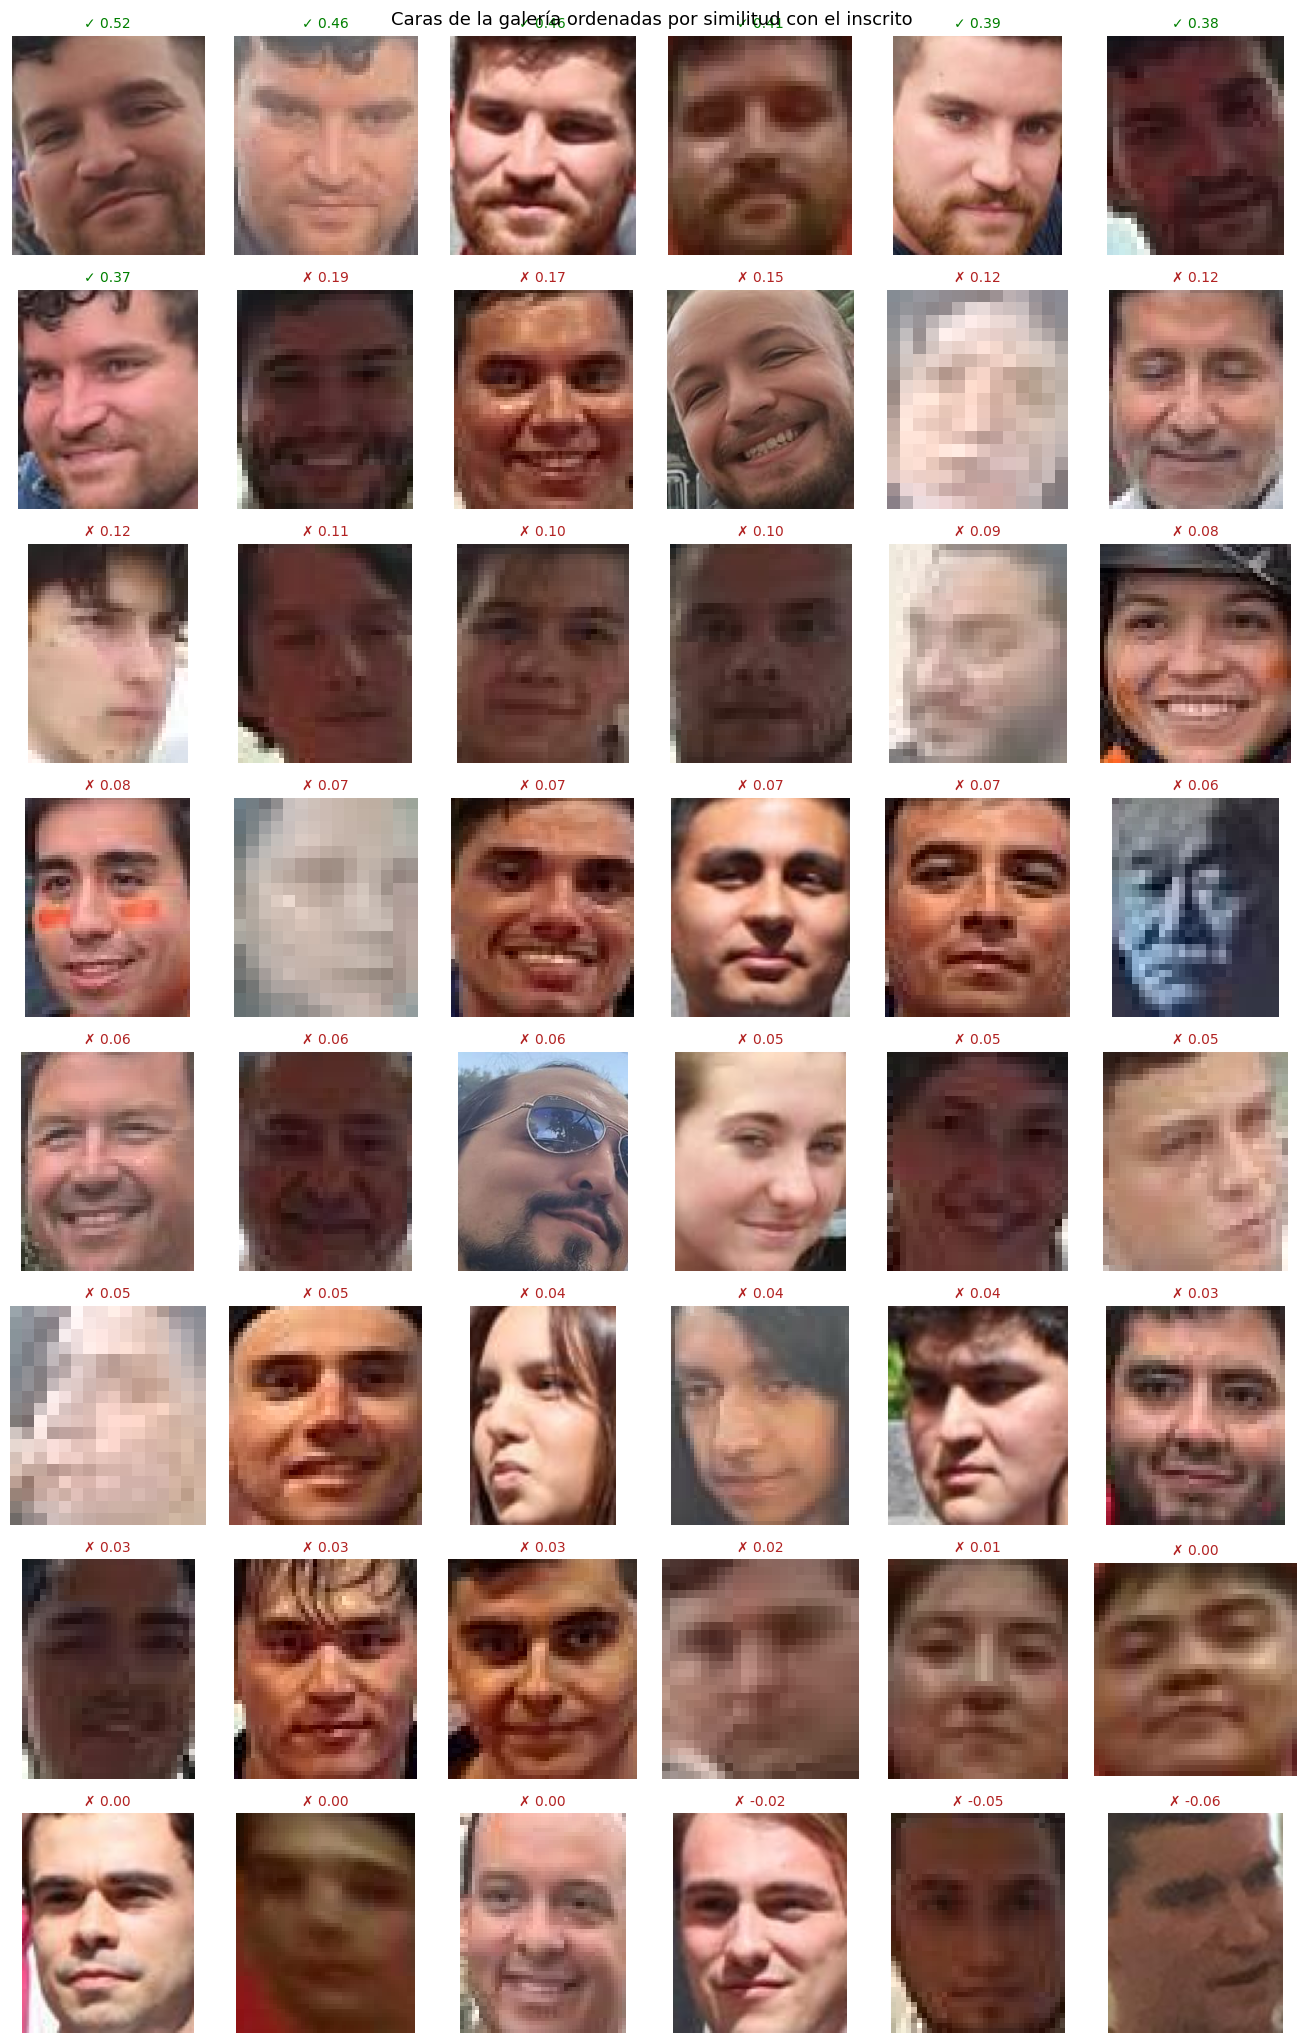

In [ ]:
# Recortamos cada cara detectada para poder mostrarla
caras_galeria = []
for b in BB:
    k, x1, y1, x2, y2 = b
    I = cv2.imread(ipath + fotos[k])
    caras_galeria.append(cv2.cvtColor(I[y1:y2, x1:x2], cv2.COLOR_BGR2RGB))

orden = np.argsort(score)[::-1]    # de mayor a menor similitud
cols = min(6, N)
filas = int(np.ceil(N / cols))
fig, ax = plt.subplots(filas, cols, figsize=(2.2 * cols, 2.6 * filas))
ax = np.array(ax).reshape(-1)
for a in ax:
    a.axis('off')
for pos, j in enumerate(orden):
    a = ax[pos]
    a.imshow(caras_galeria[j])
    ok = score[j] > UMBRAL
    a.set_title(f"{'✓' if ok else '✗'} {score[j]:.2f}",
                fontsize=10, color=('green' if ok else 'firebrick'))
fig.suptitle('Caras de la galería ordenadas por similitud con el inscrito', fontsize=13)
plt.tight_layout()
plt.show()

## 10. Puntajes de todas las caras

Una mirada complementaria: el puntaje de cada cara detectada frente al umbral. Idealmente, las caras de la persona buscada forman un grupo claramente por encima de la línea, bien separado del resto.

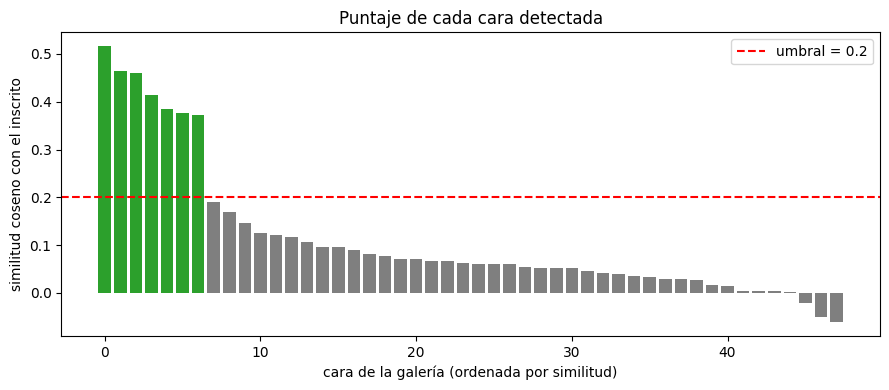

In [ ]:
fig, ax = plt.subplots(figsize=(9, 4))
colores = ['tab:green' if score[j] > UMBRAL else 'tab:gray' for j in orden]
ax.bar(range(N), score[orden], color=colores)
ax.axhline(UMBRAL, color='red', ls='--', label=f'umbral = {UMBRAL}')
ax.set_xlabel('cara de la galería (ordenada por similitud)')
ax.set_ylabel('similitud coseno con el inscrito')
ax.set_title('Puntaje de cada cara detectada')
ax.legend()
plt.tight_layout()
plt.show()

## 11. Visualización sobre las fotos

Mostramos cada foto de la galería con un **recuadro rojo** sobre las caras reconocidas como la persona inscrita. Al final, armamos una tira que pone el rostro inscrito a la izquierda y, a la derecha, todas las apariciones encontradas.

In [ ]:
dim = (256, 256)
S = cv2.resize(A, dim)
pos_txt = (25, 25)
cv2.putText(S, "Inscrito", pos_txt, cv2.FONT_HERSHEY_SIMPLEX, 1, (255, 255, 255), 3)

for k in range(m):
    I = cv2.imread(ipath + fotos[k])
    plt.figure(figsize=(12, 16))
    plt.imshow(cv2.cvtColor(I, cv2.COLOR_BGR2RGB))
    plt.title(fotos[k])
    plt.axis('off')
    for j in range(N):
        if BB[j][0] == k and detect[j]:
            _, x1, y1, x2, y2 = BB[j]
            plt.plot([x1, x1, x2, x2, x1], [y1, y2, y2, y1, y1], c='red', lw=2)
            recorte = cv2.resize(I[y1:y2, x1:x2, :], dim)
            cv2.putText(recorte, fotos[k], pos_txt, cv2.FONT_HERSHEY_SIMPLEX, 1, (255, 255, 255), 3)
            S = cv2.hconcat([S, recorte])
            print(f'rostro reconocido en {fotos[k]}  >  score = {score[j]:.4f}')
    plt.show()

# Tira resumen: inscrito + todas las apariciones encontradas
plt.figure(figsize=(15, 5))
plt.imshow(cv2.cvtColor(S, cv2.COLOR_BGR2RGB))
plt.title('Inscrito  →  apariciones encontradas en la galería')
plt.axis('off')
plt.show()

Output hidden; open in https://colab.research.google.com to view.

## 12. Sensibilidad al umbral

¿Cuántas caras acepta el sistema según dónde pongamos el umbral? Esta curva ayuda a elegirlo: un umbral muy bajo acepta casi todo (muchos falsos positivos); uno muy alto, casi nada (se pierden coincidencias válidas). El punto ideal está en la "meseta" donde solo quedan las verdaderas apariciones.

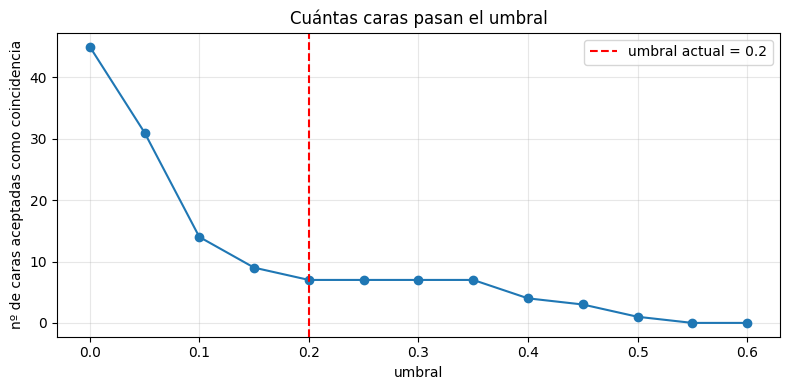

In [ ]:
umbrales = np.round(np.arange(0.0, 0.61, 0.05), 2)
n_aceptadas = [int((score > u).sum()) for u in umbrales]

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(umbrales, n_aceptadas, 'o-')
ax.axvline(UMBRAL, color='red', ls='--', label=f'umbral actual = {UMBRAL}')
ax.set_xlabel('umbral')
ax.set_ylabel('nº de caras aceptadas como coincidencia')
ax.set_title('Cuántas caras pasan el umbral')
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

---
*Cuaderno adaptado para el módulo de Visión por Computador del diplomado de inteligencia artificial aplicada a la industria tecnológica · Universidad de Santiago de Chile.*
---
<a href="https://example.com">04_buscar_cara.ipynb</a> © 2026 by <a href="https://example.com">Diego Fischer</a> is licensed under <a href="https://creativecommons.org/licenses/by/4.0/">CC BY 4.0</a><img src="https://mirrors.creativecommons.org/presskit/icons/cc.svg" alt="" style="max-width: 1em;max-height:1em;margin-left: .2em;"><img src="https://mirrors.creativecommons.org/presskit/icons/by.svg" alt="" style="max-width: 1em;max-height:1em;margin-left: .2em;">